# TG_NLDAS2_WY2012 fSCA sweep: snow cover fraction by scheme

Compares the snow-covered fraction of the ground (`FSNO`) over Tony Grove, UT, for one
snow season (WY2012: 1 Oct 2011 to 30 Jun 2012), at the Tony Grove RS SNOTEL station, across the `snow_fsca_param` schemes run by
`run_scripts/testing/sweep_fsca.sh`. All variants are clones of the base case
`TG_NLDAS2_WY2012_lastmods` and use its executable, so they differ only in the fSCA scheme.

**Output.** `TG_NLDAS2_WY20XX.sh` sets `hist_nhtfrq = -24` and `hist_mfilt = 365`, so each
variant has one h0 file of daily means, in `$OUTPUT_ROOT/<case>_<variant>/run/`.

Model SWE is compared with the station's observed SWE, loaded with the `model_datasets`
package (`../model_data_loader`), which reads the PNNL bias-corrected, quality-controlled
SNOTEL data set.

For now only CZ26, SL12 and NY07 are loaded (see `VARIANTS` below).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import xarray as xr
from dotenv import find_dotenv, load_dotenv
from model_datasets.snotel import PNNLSnotel

BASE = "TG_NLDAS2_WY2012_lastmods"
VARIANTS = ["CZ26", "SL12", "NY07"]   # add AR25 etc. here once those runs are sorted out
START = "2011-10-01"                  # first day of the history file name
END = "2012-06-30"                    # last day of the run
SITE_NAME = "Tony Grove RS"           # SNOTEL site name as in the PNNL summary file

# Paths come from the .env file in the repo root (found by searching up from here)
env_file = find_dotenv(usecwd=True)
if not env_file:
    raise FileNotFoundError("No .env file found in this directory or above it")
load_dotenv(env_file, override=True)
OUTPUT_ROOT = Path(os.environ["OUTPUT_ROOT"])   # model output, one folder per case
# Local copy of the fsurdat file used by the runs (the run script's surfdataFile)
SURFDATA_FILE = Path(os.environ["DATA_ROOT"]) / "surfdata_TG_UT_0125_c261028_merged.nc"
# PNNL SNOTEL data: holds SNOTEL_Detre.csv and bcqc_data_v2/
SNOTEL_PATH = os.environ["SNOTEL_PATH"]

## Load the data

`open_history` opens one variant's h0 file. ELM writes a record at step 0 (the first
half-hour time step), which isn't a daily mean, so it is dropped. Each record's time stamp
is the *end* of its averaging interval (e.g. the 1 Oct mean is stamped 2 Oct 00:00), so the
times are moved to the interval midpoints from `time_bounds`. ELM uses a `noleap` calendar;
converting to `datetime64` makes plotting easier and is safe for these dates (there is no
29 Feb in the noleap calendar, so 29 Feb 2012 is simply missing).

The grid cells' elevation comes from `TOPO` in the surface data file, not from the history
file's `topo`, which is the atmosphere's surface height from the coupler; DATM leaves it at
0 m. The surface data file is on dimensions `lsmlat, lsmlon`, the same 12 × 8 grid as the
history files.

In [2]:
def open_history(variant):
    case = f"{BASE}_{variant}"
    f = OUTPUT_ROOT / case / "run" / f"{case}.elm.h0.{START}-00000.nc"
    ds = xr.open_dataset(f)
    ds = ds.isel(time=slice(1, None))            # drop the step-0 record
    t0, t1 = ds["time_bounds"].values.T          # cftime objects
    ds = ds.assign_coords(time=t0 + (t1 - t0) / 2)
    return ds.convert_calendar("standard", use_cftime=False)

runs = {v: open_history(v) for v in VARIANTS}
for v, ds in runs.items():
    print(f"{v}: {ds.sizes['time']} days, {ds.time.values[0]} .. {ds.time.values[-1]}, "
          f"grid {ds.sizes['lat']} x {ds.sizes['lon']}")

ref = runs[VARIANTS[0]]
surf = xr.open_dataset(SURFDATA_FILE)
# Check that the surfdata grid lines up with the history grid before relabeling it
assert (abs(surf["LATIXY"].isel(lsmlon=0).values - ref.lat.values).max() < 1e-4 and
        abs(surf["LONGXY"].isel(lsmlat=0).values - ref.lon.values).max() < 1e-4)
topo = xr.DataArray(surf["TOPO"].values, coords={"lat": ref.lat, "lon": ref.lon})

CZ26: 273 days, 2011-10-01T12:00:00.000000000 .. 2012-06-30T12:00:00.000000000, grid 12 x 8
SL12: 273 days, 2011-10-01T12:00:00.000000000 .. 2012-06-30T12:00:00.000000000, grid 12 x 8
NY07: 273 days, 2011-10-01T12:00:00.000000000 .. 2012-06-30T12:00:00.000000000, grid 12 x 8


## SNOTEL observations at Tony Grove RS

`PNNLSnotel` looks up the site in the PNNL summary file and uses the more precise location
from `SNOTEL_Detre.csv` when there is one. `load_data()` then reads the daily record and
converts it to metric units (`swe_mm`, `precip_mm`, `T_*_C`). Its index is local time
(America/Denver); the time zone is dropped here so that it lines up with the model dates.

The model grid cell is the one whose 0.125° box contains the station (`method="nearest"`
on the cell centers). ELM's history longitudes run 0–360°, so the station's longitude is
shifted to match.

In [3]:
site = PNNLSnotel(SITE_NAME, storage_path=SNOTEL_PATH)
site.load_data()
obs = site.data.loc[START:END].copy()
obs.index = obs.index.tz_localize(None)

near = dict(lat=site.latitude, lon=site.longitude % 360, method="nearest")
cell = topo.sel(**near)
print(f"{SITE_NAME}: {site.latitude:.4f}N, {site.longitude:.4f}E, {site.elevation:.0f} m "
      f"(precise location: {site.precise_location})")
print(f"nearest cell: {float(cell.lat):.4f}N, {float(cell.lon) - 360:.4f}E, "
      f"mean elevation {float(cell):.0f} m")
print(f"obs: {len(obs)} days, {obs['swe_mm'].isna().sum()} missing SWE, "
      f"peak SWE {obs['swe_mm'].max():.0f} mm on {obs['swe_mm'].idxmax():%d %b %Y}")

Tony Grove RS: 41.8857N, -111.5693E, 1928 m (precise location: True)
nearest cell: 41.9375N, -111.5625E, mean elevation 1856 m
obs: 274 days, 0 missing SWE, peak SWE 297 mm on 07 Mar 2012


## fSCA and SWE at Tony Grove RS

Top: `FSNO`, the daily-mean fraction of the ground covered by snow, in the cell nearest the
station. There's no fSCA observation at the station.

Bottom: SWE. The model's `H2OSNO` (mm of liquid water) is the snow water of the whole cell,
including any snow-free part, so when `FSNO` < 1 it's lower than the SWE under the snow.
SNOTEL measures a single point under continuous snow. The model also stands for a whole cell
whose mean elevation can differ from the station's (see above). The SNOTEL value is a
once-daily reading and the model value is a daily mean over a UTC day, so the two can be up
to a day apart. That doesn't matter at this time scale.

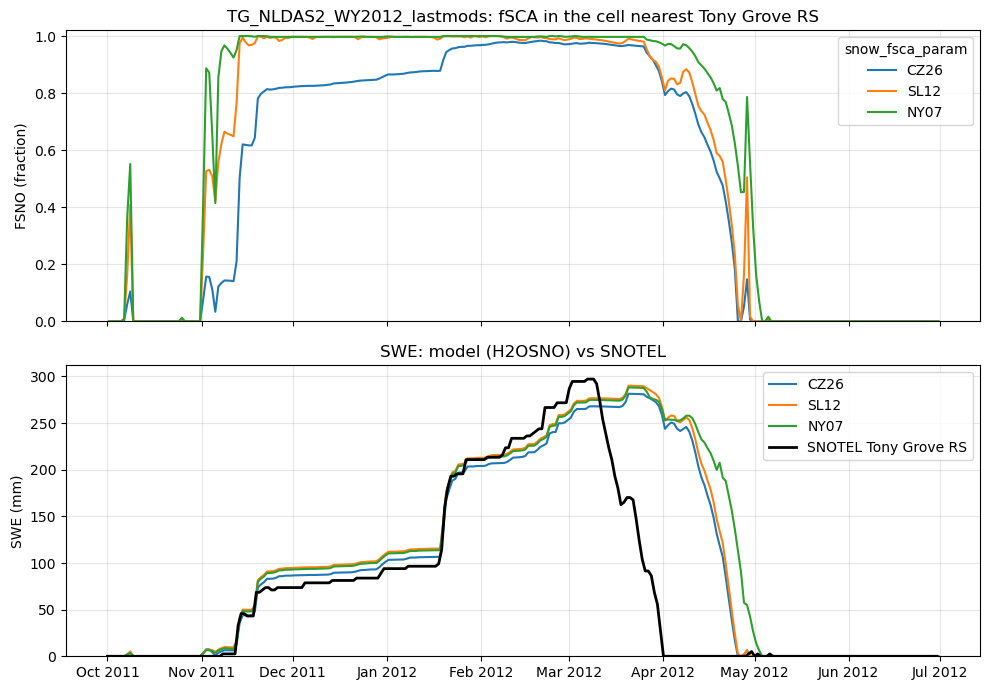

In [4]:
fig, (ax_f, ax_s) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for v, ds in runs.items():
    pt = ds.sel(**near)
    pt["FSNO"].plot(ax=ax_f, label=v)
    pt["H2OSNO"].plot(ax=ax_s, label=v)
ax_s.plot(obs.index, obs["swe_mm"], color="k", lw=2, label=f"SNOTEL {SITE_NAME}")

ax_f.set(title=f"{BASE}: fSCA in the cell nearest {SITE_NAME}",
         xlabel="", ylabel="FSNO (fraction)", ylim=(0, 1.02))
ax_f.legend(title="snow_fsca_param")
ax_s.set(title="SWE: model (H2OSNO) vs SNOTEL", xlabel="", ylabel="SWE (mm)", ylim=(0, None))
ax_s.legend()
for ax in (ax_f, ax_s):
    ax.grid(alpha=0.3)
ax_s.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout()
plt.show()

## fSCA at the highest and lowest grid cells

The schemes may differ the most at the extremes of the elevation range, so here is fSCA in
the grid cells with the highest and lowest mean elevation (`TOPO`).

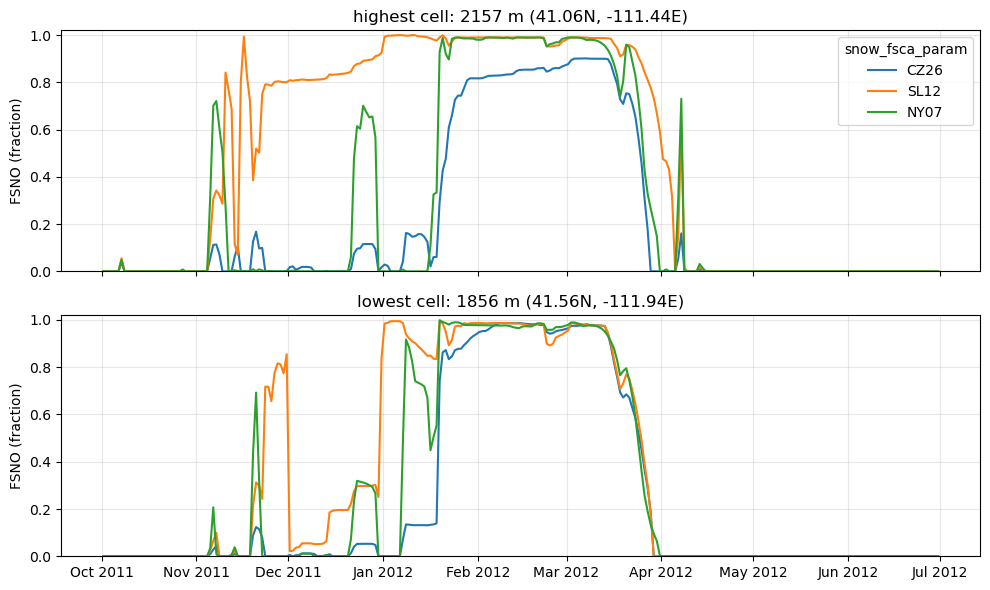

In [4]:
cells = {"highest": topo.argmax(("lat", "lon")), "lowest": topo.argmin(("lat", "lon"))}

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, sharey=True)
for ax, (name, idx) in zip(axes, cells.items()):
    for v, ds in runs.items():
        ds["FSNO"].isel(idx).plot(ax=ax, label=v)
    c = topo.isel(idx)
    ax.set(title=f"{name} cell: {float(c):.0f} m "
                 f"({float(c.lat):.2f}N, {float(c.lon) - 360:.2f}E)",
           xlabel="", ylabel="FSNO (fraction)", ylim=(0, 1.02))
    ax.grid(alpha=0.3)
axes[0].legend(title="snow_fsca_param")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout()
plt.show()